# Procedural transformations on time-series windows

We transform windows cut from five synthetic recordings with the three transformations of `kcai-data-sampling-timeseries`:

| Transformation | Parameters | Support | Randomness |
|---|---|---|---|
| `low_pass` | `cutoff`, cycles per step in `(0, 0.5]` | global: each output step depends on the whole window | none |
| `add_sinusoid` | `frequency` (cycles per step), `amplitude`, `phase` | pointwise | none |
| `jitter` | `sigma`, in the units of the signal | pointwise | `seed` |

The sample is a **window**: `W` consecutive steps of one series over `C` channels. A transformation receives a batch `(B, W, C)` of float windows, with axes `(time, channel)` and no value range, and returns a batch of the same shape. The `timeseries_parquet` loader cuts the windows. Each window carries its **key**: `series_id`, `start_window`, `end_window` and, optionally, `t0_series`. Every relation between two windows (same series, overlap, order and lag, simultaneity) is computed from it.

Frequencies are in **cycles per step**: a transformation sees the window array only, not the sampling rate. At 100 Hz, `f` Hz is `f / 100`.

The data is generated by `scripts/make_timeseries_sample.py`, with nothing downloaded: five recordings of 2,000 steps at 100 Hz. Channel 0, "vibration", is a 3 Hz sinusoid plus a weaker 20 Hz component. Channel 1, "temperature", is a slow drift with a step halfway through, plus noise.

To run it from the repository root: `uv run --with jupyterlab --with matplotlib jupyter lab examples/notebooks/timeseries-transformations.ipynb`. `matplotlib` is used for the plots only.

## Setup

In [1]:
import os
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import yaml

%config InlineBackend.figure_format = 'png'
pd.set_option("display.max_colwidth", None)

# Work from the repository root: every path in the config is relative to it.
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".git").exists())
os.chdir(REPO)

from kcai_data_sampling_job.cli import run
from kcai_data_sampling_job.dataloaders.api.timeseries import TimeSeriesLoaderConfig, TimeSeriesParquetDataLoader
from kcai_data_sampling_timeseries.api.transformations import AddSinusoid, Jitter, LowPass

subprocess.run([sys.executable, "scripts/make_timeseries_sample.py"], check=True)

with open("examples/config/timeseries-procedural.yaml") as f:
    CFG = yaml.safe_load(f)
LOADER = CFG["dataloaders"]["loaders"][0]
FS = LOADER["sampling_rate"]  # Hz
print(yaml.safe_dump(CFG, sort_keys=False))

wrote 5 series of 2000 steps at 100 Hz to /home/lucasschott/TechLab/kcai-data-sampling/examples/data/timeseries_sample/series.parquet
dataloaders:
  loaders:
  - name: machines
    type: timeseries_parquet
    path: examples/data/timeseries_sample/series.parquet
    id_column: series_id
    values_column: values
    sampling_rate: 100
    load_batch_size: 32
    windows:
      mode: consecutive
      window: 256
      stride: 128
operations:
  outputs:
    path: examples/outputs/{selection}/ledger.parquet
    write_samples: true
    samples_dir: examples/outputs/{selection}/payloads
    payload_format: npy
    flush_batch_size: 128
    include:
    - series_id
    - start_window
    - end_window
  transformations:
  - name: low_pass
    type: low_pass
    cutoff:
      range:
      - 0.05
      - 0.15
      samples: 3
      mode: even
  - name: interference_25hz
    type: add_sinusoid
    frequency: 0.25
    amplitude: 0.2
  - name: sensor_noise
    type: jitter
    sigma: 0.1
    seed

## 1. The series

One row per series: an id, the values (`list<list<float>>`, 2,000 steps of 2 channels) and `machine`, a source column. Here is the first recording.

series_id: string
values: list<element: list<element: double>>
  child 0, element: list<element: double>
      child 0, element: double
machine: string


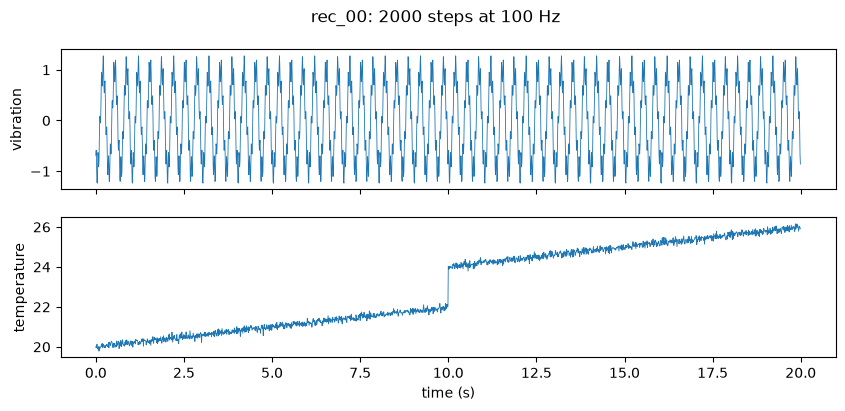

In [2]:
table = pq.read_table(LOADER["path"])
print(table.schema)

series = np.asarray(table.column("values")[0].as_py())  # (T, C)
t = np.arange(len(series)) / FS
fig, axes = plt.subplots(2, 1, figsize=(10, 4), sharex=True)
for c, (ax, name) in enumerate(zip(axes, ["vibration", "temperature"])):
    ax.plot(t, series[:, c], lw=0.6)
    ax.set_ylabel(name)
axes[1].set_xlabel("time (s)")
fig.suptitle(f"{table.column('series_id')[0]}: {len(series)} steps at {FS:g} Hz")
plt.show()

## 2. Windows and their key

The example config cuts **consecutive** windows of `W = 256` steps every `stride = 128` steps: 14 windows per series, each sharing 128 steps with the next one.

`windows_of` reads every window of a selection, as a job would. The ids are opaque: a 12-hex hash of `(series, start, end)`. Relations are read from the key columns, never from the id.

In [3]:
def windows_of(windows, **loader):
    # Every window of the selection: the (N, W, C) stack and its key table.
    config = TimeSeriesLoaderConfig.model_validate({**LOADER, **loader, "windows": windows})
    (selection,) = TimeSeriesParquetDataLoader(config.name, config).get_selections()
    selection.bootstrap(None)
    batches = list(selection)
    keys = pd.concat([b.columns.to_pandas().assign(id=b.ids) for b in batches], ignore_index=True)
    return np.concatenate([b.data for b in batches]), keys.drop(columns="machine")


data, keys = windows_of(LOADER["windows"])
print(f"{len(keys)} windows, data {data.shape} {data.dtype}")
keys.head(4)

70 windows, data (70, 256, 2) float64


,series_id,start_window,end_window,id
0,rec_00,0,255,b9453a8a0b03
1,rec_00,128,383,6be723afd9fc
2,rec_00,256,511,b1edd41d7167
3,rec_00,384,639,8f657dd5ef18


Relations between two windows are computed from the key, never stored. For two windows of the same series, the shared steps are `max(0, min(e₁, e₂) − max(s₁, s₂) + 1)`. When `s₂ > e₁`, window 1 precedes window 2 by a lag of `s₂ − e₁ − 1` steps: windows 0 and 2 touch (lag 0), windows 0 and 3 are 128 steps apart. Window 14 is the first of the next series.

In [4]:
def relation(a, b):
    if a.series_id != b.series_id:
        return "different series"
    shared = max(0, min(a.end_window, b.end_window) - max(a.start_window, b.start_window) + 1)
    if shared:
        return f"overlap of {shared} steps"
    return f"lag of {b.start_window - a.end_window - 1} steps"


rows = keys.itertuples()
w = {i: r for i, r in enumerate(rows)}
for i, j in [(0, 1), (0, 2), (0, 3), (13, 14)]:
    print(f"window {i:>2} vs {j:>2}: {relation(w[i], w[j])}")

window  0 vs  1: overlap of 128 steps
window  0 vs  2: lag of 0 steps
window  0 vs  3: lag of 128 steps
window 13 vs 14: different series


**Independent** windows are drawn: `n_windows` positions per series, seeded by `seed` and the series id. With `non_overlap: true`, no two windows of a series share a step. The same seed gives the same windows. An id depends only on `(series, start, end)`, so a window gets the same id whichever mode cut it.

In [5]:
independent = {"mode": "independent", "window": 256, "n_windows": 3, "non_overlap": True, "seed": 1}
_, drawn = windows_of(independent)
_, again = windows_of(independent)
_, other = windows_of({**independent, "seed": 2})
print("same seed, same windows:", drawn.equals(again))
print("other seed, other windows:", not drawn[["start_window"]].equals(other[["start_window"]]))
drawn.head(6)

same seed, same windows: True
other seed, other windows: True


,series_id,start_window,end_window,id
0,rec_00,567,822,20d2f6709853
1,rec_00,1007,1262,fb5b919337bb
2,rec_00,1549,1804,caf41569062f
3,rec_01,402,657,a44fcac05960
4,rec_01,1039,1294,dcd06ef4dc2b
5,rec_01,1520,1775,dbf4936ba0b3


## 3. Applying a transformation

`transform` builds a transformation from its config, as a job would, and applies it to a batch. `rngs` gives a stochastic transformation one random generator per window, seeded by `seed`, the window id and the parameters; it returns `None` for a deterministic one.

We work on the 14 windows of `rec_00`.

In [6]:
mask = (keys.series_id == "rec_00").to_numpy()
x, ids = data[mask], keys.id[mask].tolist()


def transform(cls, xs=None, window_ids=None, **params):
    xs = x if xs is None else xs
    transformation = cls(params)
    return transformation.apply(xs, transformation.rngs(ids if window_ids is None else window_ids))


def spectrum(window):
    # Amplitude spectrum of one channel, in Hz.
    return np.fft.rfftfreq(len(window), 1 / FS), np.abs(np.fft.rfft(window)) / len(window) * 2

## 4. `low_pass`: frequencies above `cutoff` are set to zero

At `cutoff = 0.1` cycles per step, i.e. 10 Hz at 100 Hz, the 20 Hz component of the vibration channel is removed and the 3 Hz one is kept. It is an ideal FFT filter: each output step depends on the whole window.

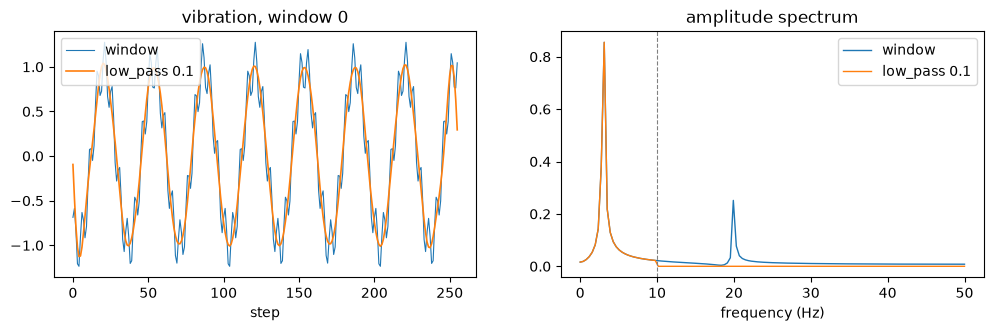

In [7]:
filtered = transform(LowPass, cutoff=0.1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.2))
steps = np.arange(x.shape[1])
ax1.plot(steps, x[0, :, 0], lw=0.8, label="window")
ax1.plot(steps, filtered[0, :, 0], lw=1.2, label="low_pass 0.1")
ax1.set_xlabel("step")
ax1.set_title("vibration, window 0")
ax1.legend()
for xs_, label in [(x, "window"), (filtered, "low_pass 0.1")]:
    f, a = spectrum(xs_[0, :, 0])
    ax2.plot(f, a, lw=1, label=label)
ax2.axvline(0.1 * FS, color="grey", ls="--", lw=0.8)
ax2.set_xlabel("frequency (Hz)")
ax2.set_title("amplitude spectrum")
ax2.legend()
plt.show()

The example config sweeps `cutoff` over 0.05, 0.10 and 0.15, i.e. 5, 10 and 15 Hz. All three fall between the 3 Hz and the 20 Hz components, so one could expect the same vibration output. It is not: 3 Hz makes 7.68 periods in 256 steps, not a whole number, so it does not sit on one FFT bin. Its energy leaks over every frequency, and each cutoff keeps a different part of it. On the temperature channel the noise covers every frequency anyway.

In [8]:
outs = {c: transform(LowPass, cutoff=c) for c in (0.05, 0.1, 0.15)}
for channel, name in enumerate(["vibration", "temperature"]):
    gap = max(np.abs(outs[a][..., channel] - outs[b][..., channel]).max() for a, b in [(0.05, 0.1), (0.1, 0.15)])
    print(f"{name:<12} largest difference between neighbouring cutoffs: {gap:.3g}")

vibration    largest difference between neighbouring cutoffs: 0.471
temperature  largest difference between neighbouring cutoffs: 0.583


**Overlapping windows are transformed separately.** Windows 0 and 1 share steps 128 to 255. A deterministic pointwise transformation would give the same values on them. `low_pass` reads the whole window, so the two windows give two different outputs for the same steps. The FFT treats a window as periodic: it sees the jump from the last value back to the first one, and the filter rings at both edges of the window. On the temperature channel of window 7 (series steps 896 to 1,151), the jump is about 2.5 degrees: the output rings at both edges, and around the step at series step 1,000.

window 0 vs 1 on their 128 shared steps, largest difference: vibration 0.676, temperature 0.236
before the filter: 0


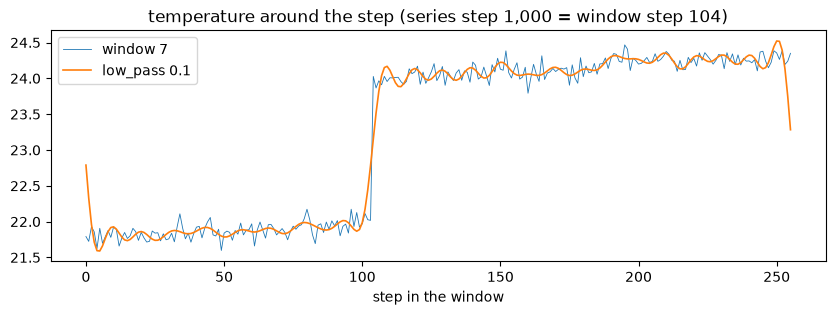

In [9]:
shared = np.abs(filtered[0, 128:] - filtered[1, :128]).max(axis=0)
print(f"window 0 vs 1 on their 128 shared steps, largest difference: vibration {shared[0]:.3g}, temperature {shared[1]:.3g}")
print(f"before the filter: {np.abs(x[0, 128:] - x[1, :128]).max():.3g}")

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(steps, x[7, :, 1], lw=0.6, label="window 7")
ax.plot(steps, filtered[7, :, 1], lw=1.2, label="low_pass 0.1")
ax.set_xlabel("step in the window")
ax.set_title("temperature around the step (series step 1,000 = window step 104)")
ax.legend()
plt.show()

## 5. `add_sinusoid`: an interference at a known frequency

The example config adds a 25 Hz interference (`frequency: 0.25`) with `amplitude: 0.2`. The output minus the input is exactly the requested wave, on every window and channel. The phase is counted from each window's first step. With `stride = 128`, two windows start 128 steps apart. At 0.25 cycles per step that is 32 whole periods, so they add the same values on their shared steps. At 0.1 cycles per step, 12.8 periods, they do not.

output - input is the wave: True
frequency 0.25: added values differ on the shared steps by up to 7.33e-15
frequency 0.1: added values differ on the shared steps by up to 0.235


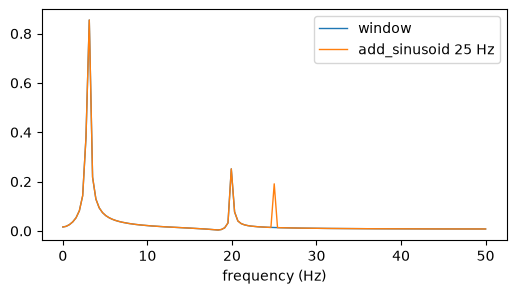

In [10]:
noisy = transform(AddSinusoid, frequency=0.25, amplitude=0.2)
wave = 0.2 * np.sin(2 * np.pi * 0.25 * steps)
print("output - input is the wave:", np.allclose(noisy - x, wave[None, :, None]))

for frequency in (0.25, 0.1):
    out = transform(AddSinusoid, frequency=frequency, amplitude=0.2)
    gap = np.abs((out - x)[0, 128:] - (out - x)[1, :128]).max()
    print(f"frequency {frequency}: added values differ on the shared steps by up to {gap:.3g}")

f, a = spectrum(noisy[0, :, 0])
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(*spectrum(x[0, :, 0]), lw=1, label="window")
ax.plot(f, a, lw=1, label="add_sinusoid 25 Hz")
ax.set_xlabel("frequency (Hz)")
ax.legend()
plt.show()

## 6. `jitter` and the seed

`jitter` adds independent Gaussian noise of standard deviation `sigma` to every step and channel. It draws random numbers, so it **requires** a `seed`, and the seed is recorded on every output row. Each window draws from its own generator, seeded by the seed, its id and the parameters, not by its position in a batch.

What the seed guarantees:

In [11]:
SIGMA = 0.1
base = transform(Jitter, sigma=SIGMA, seed=7)
noise = base - x

print(f"noise mean {noise.mean():+.4f}, std {noise.std():.4f} (sigma {SIGMA})")
print("same seed, same output:     ", np.array_equal(base, transform(Jitter, sigma=SIGMA, seed=7)))
print("other seed, other output:   ", not np.array_equal(base, transform(Jitter, sigma=SIGMA, seed=8)))

# The batch split and the order do not matter: each window keeps its own draw.
one_by_one = np.concatenate([transform(Jitter, x[i : i + 1], [ids[i]], sigma=SIGMA, seed=7) for i in range(len(x))])
order = np.random.default_rng(0).permutation(len(x))
shuffled = transform(Jitter, x[order], [ids[i] for i in order], sigma=SIGMA, seed=7)
print("window by window = batch:   ", np.array_equal(one_by_one, base))
print("shuffled batch, same draws: ", np.array_equal(shuffled, base[order]))

try:
    Jitter({"sigma": SIGMA})
except ValueError as error:
    print("no seed:", error)

noise mean -0.0013, std 0.1000 (sigma 0.1)
same seed, same output:      True
other seed, other output:    True
window by window = batch:    True
shuffled batch, same draws:  True
no seed: jitter: a stochastic algorithm requires a seed; set 'seed' in the transformation config (deterministic algorithms record None)


The parameters enter the seed too. Two values of `sigma` in a sweep therefore draw **independent** noises, not one noise scaled: the variants of one window are not correlated.

correlation between the sigma=0.1 and sigma=0.2 noises: -0.007


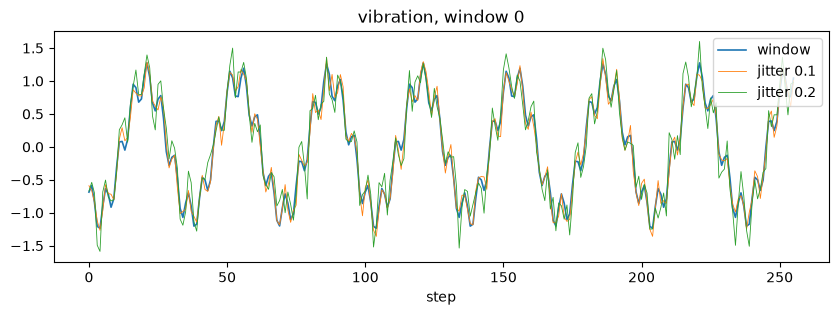

In [12]:
small = transform(Jitter, sigma=0.1, seed=7) - x
large = transform(Jitter, sigma=0.2, seed=7) - x
print(f"correlation between the sigma=0.1 and sigma=0.2 noises: {np.corrcoef(small.ravel(), large.ravel())[0, 1]:+.3f}")

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(steps, x[0, :, 0], lw=1.2, label="window")
ax.plot(steps, (x + small)[0, :, 0], lw=0.6, label="jitter 0.1")
ax.plot(steps, (x + large)[0, :, 0], lw=0.6, label="jitter 0.2")
ax.set_xlabel("step")
ax.set_title("vibration, window 0")
ax.legend()
plt.show()

## 7. The whole job

The same config, run as the CLI runs it (`kcai-data-sampling process -p examples/config/timeseries-procedural.yaml`). It writes one ledger row and one `.npy` payload per (window, transformation): 70 windows × 5 transformations, with the `low_pass` sweep expanded into three.

In [13]:
summary = run({**CFG, "compute": {"progress_bar": False}})
print(summary)

ledger_path = CFG["operations"]["outputs"]["path"].format(selection=LOADER["name"])
ledger = pd.read_parquet(ledger_path)
ledger["seed"] = ledger.seed.astype("Int64")  # NULL for the deterministic rows
print(ledger.columns.tolist())
ledger.groupby(["algorithm", "params"], sort=False).agg(rows=("id", "size"), seed=("seed", "first"))

{'machines': 350}


['selection', 'dataloader', 'parent_id', 'id', 'algorithm', 'family', 'arity', 'reversible', 'params', 'seed', 'tool_model', 'target_model', 'artifact', 'series_id', 'start_window', 'end_window']


rows  seed
algorithm    params                                                         
low_pass     {"cutoff": 0.05}                                       70  <NA>
             {"cutoff": 0.1}                                        70  <NA>
             {"cutoff": 0.15}                                       70  <NA>
add_sinusoid {"amplitude": 0.2, "frequency": 0.25, "phase": 0.0}    70  <NA>
jitter       {"sigma": 0.1}                                         70     7

Each row is enough to replay its output. For a `jitter` row, we take its parent window by `parent_id`, rebuild the transformation from `params` and `seed`, and recompute the payload bit for bit.

In [14]:
import json

row = ledger[ledger.algorithm == "jitter"].iloc[3]
payloads = Path(CFG["operations"]["outputs"]["samples_dir"].format(selection=LOADER["name"]))
payload = np.load(payloads / row.artifact)

parent = data[(keys.id == row.parent_id).to_numpy()]
replayed = transform(Jitter, parent, [row.parent_id], **json.loads(row.params), seed=int(row.seed))
print(row[["id", "parent_id", "series_id", "start_window", "end_window", "seed"]].to_dict())
print(f"noise std of this payload: {(payload - parent[0]).std():.3f}")
print("replayed from the row:", np.array_equal(payload, replayed[0]))

{'id': 'fc60bba6f6e5', 'parent_id': '8f657dd5ef18', 'series_id': 'rec_00', 'start_window': 384, 'end_window': 639, 'seed': 7}
noise std of this payload: 0.105
replayed from the row: True


## Takeaways

- **The key is enough to relate windows.** Consecutive windows of 256 steps every 128 give 14 windows per series, 70 in all. Overlap (128 steps), adjacency (lag 0) and lag (128 steps) are computed from `series_id`, `start_window` and `end_window`; the ids are opaque hashes and are never parsed.
- **Independent windows are reproducible.** The same `seed` draws the same windows, another seed draws others.
- **`low_pass` removes the 20 Hz component at a 10 Hz cutoff, but it is an ideal FFT filter on a short window.** It treats the window as periodic, so it rings at the window edges. Two overlapping windows give different outputs on the steps they share (up to 0.68 on vibration, 0.24 on temperature), and the 5, 10 and 15 Hz cutoffs give different vibration outputs (up to 0.47), because 3 Hz does not fall on an FFT bin of a 256-step window.
- **`add_sinusoid` adds exactly the requested wave**, with its phase counted from each window's first step. At 25 Hz the stride holds 32 whole periods and overlapping windows add the same values; at 10 Hz they differ by up to 0.24.
- **`jitter` is reproducible and batch-independent.** Its noise has standard deviation 0.1000 for `sigma = 0.1`. The same seed gives the same output, another seed another one; window by window, as one batch or shuffled, each window gets the same draw. Without a seed it is refused. Two values of `sigma` draw independent noises (correlation −0.007), not one noise scaled.
- **The ledger replays each output.** The job writes 350 rows (70 windows × 5 transformations). `seed` is 7 on the `jitter` rows and NULL on the deterministic ones, and a `jitter` payload is recomputed bit for bit from its row and its parent window.